In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))
import pandas as pd
import gc 
import matplotlib.pyplot as plt
import config
import negative_sampling as ns
import dataset_build as db

DEMO_YEAR = config.PROCESSING_YEARS[0]



In [2]:
panel = db.load_analysis_dataset(years=[DEMO_YEAR])

n_rows = len(panel)
n_fire = int(panel["fire"].sum())
print(f"Panel rows:      {n_rows:,}")
print(f"Grid cells:      {panel['grid_id'].nunique():,}")
print(f"Date range:      {panel['date'].min().date()} to {panel['date'].max().date()}")
print(f"Fire cell-days:  {n_fire:,} ({n_fire / n_rows * 100:.2f}%)")
print()
print(f"A model that always answers 'no fire' would be {(n_rows - n_fire) / n_rows * 100:.1f}% accurate")
print(f"while finding 0 of the {n_fire:,} fires.")

Panel rows:      9,407,664
Grid cells:      25,704
Date range:      2020-01-01 to 2020-12-31
Fire cell-days:  348,278 (3.70%)

A model that always answers 'no fire' would be 96.3% accurate
while finding 0 of the 348,278 fires.


In [3]:
panel_by_month = ns.class_balance(panel, by="month")
panel_by_month

,month,rows,fire_rows,non_fire_rows,fire_rate_pct
0,1,796824,50866,745958,6.4
1,2,745416,81196,664220,10.9
2,3,796824,113480,683344,14.2
3,4,771120,61060,710060,7.9
4,5,796824,15466,781358,1.9
5,6,771120,2307,768813,0.3
6,7,796824,2024,794800,0.3
7,8,796824,1712,795112,0.2
8,9,771120,1488,769632,0.2
9,10,796824,904,795920,0.1


In [4]:
ns.neighbour_grid_ids("18.5_99.0", buffer_cells=1)

['18.4_98.9',
 '18.4_99.0',
 '18.4_99.1',
 '18.5_98.9',
 '18.5_99.0',
 '18.5_99.1',
 '18.6_98.9',
 '18.6_99.0',
 '18.6_99.1']

In [5]:
buffer_options = [(0, 0), (1, 0), (0, 1), (1, 1), (2, 2)]

rows = []
for buffer_cells, buffer_days in buffer_options:
    marked = ns.mark_near_fire(panel, buffer_cells, buffer_days, verbose=False)
    negatives = marked[marked["fire"] == 0]
    march = negatives[negatives["month"] == 3]
    rows.append({
        "buffer_cells": buffer_cells,
        "buffer_days": buffer_days,
        "excluded_pct": round(negatives["near_fire"].mean() * 100, 1),
        "usable_negatives": int((negatives["near_fire"] == 0).sum()),
        "usable_march_negatives": int((march["near_fire"] == 0).sum()),
    })
    del marked, negatives, march
    gc.collect()

buffer_table = pd.DataFrame(rows)
buffer_table

,buffer_cells,buffer_days,excluded_pct,usable_negatives,usable_march_negatives
0,0,0,0.0,9059386,683344
1,1,0,9.5,8200949,480431
2,0,1,3.7,8725534,593682
3,1,1,16.6,7552969,389008
4,2,2,29.0,6428443,309775


In [6]:
sample, report = ns.build_training_sample(panel, ratio=3, buffer_cells=1, buffer_days=1, seed=42)

Buffer: 1 cell(s) (~11 km), 1 day(s)
  Non-fire rows:            9,059,386
  Inside a fire buffer:     1,506,417 (16.6%)
  Usable as negatives:      7,552,969
Training sample: 1,393,112 rows
  Fire rows (all kept):     348,278
  Non-fire rows sampled:    1,044,834 (ratio 1 : 3.0)
  Fire rate: panel 3.7% -> sample 25.0%


In [7]:
pd.Series(report, name="value", dtype="object").to_frame()

,value
panel_rows,9407664
fire_rows,348278
non_fire_rows,9059386
excluded_near_fire,1506417
negative_pool,7552969
negatives_sampled,1044834
negatives_not_used,8014552
sample_rows,1393112
ratio_requested,3
ratio_actual,3.0


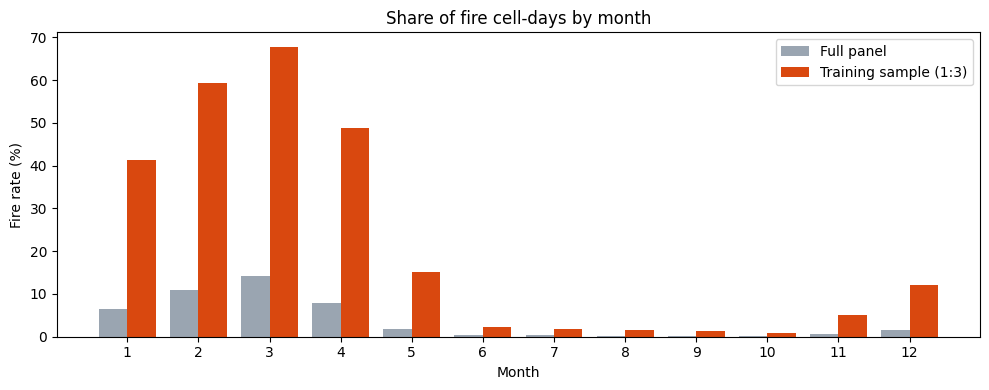

In [8]:
sample_by_month = ns.class_balance(sample, by="month")

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.4
months = panel_by_month["month"]
ax.bar(months - width / 2, panel_by_month["fire_rate_pct"], width, label="Full panel", color="#9aa5b1")
ax.bar(months + width / 2, sample_by_month["fire_rate_pct"], width, label="Training sample (1:3)", color="#d9480f")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Fire rate (%)")
ax.set_title("Share of fire cell-days by month")
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
marked_panel = ns.mark_near_fire(panel, buffer_cells=1, buffer_days=1, verbose=False)
weather_columns = ["temp_max_c", "rainfall_7d_mm", "dry_days", "wind_speed_kmh", "soil_moisture"]

is_fire = marked_panel["fire"] == 1
is_near = marked_panel["near_fire"] == 1
group_masks = {
    "fire rows": is_fire,
    "all non-fire rows": ~is_fire,
    "excluded by buffer": is_near,
    "usable negatives": ~is_fire & ~is_near,
}

profile_rows = []
for name, mask in group_masks.items():
    row = {"group": name, "rows": int(mask.sum())}
    for column in weather_columns:
        row[column] = round(marked_panel.loc[mask, column].mean(), 3)
    profile_rows.append(row)

sampled_negatives = sample[sample["fire"] == 0]
row = {"group": "sampled negatives", "rows": len(sampled_negatives)}
for column in weather_columns:
    row[column] = round(sampled_negatives[column].mean(), 3)
profile_rows.append(row)

del marked_panel, is_fire, is_near, group_masks, sampled_negatives
gc.collect()

pd.DataFrame(profile_rows).set_index("group")

,rows,temp_max_c,rainfall_7d_mm,dry_days,wind_speed_kmh,soil_moisture
group,,,,,,
fire rows,348278,32.280,6.160,26.391,5.896,0.247
all non-fire rows,9059386,25.829,51.666,5.313,5.545,0.377
excluded by buffer,1506417,31.014,13.567,17.417,5.813,0.276
usable negatives,7552969,24.795,59.265,2.899,5.492,0.397
sampled negatives,1044834,24.796,59.201,2.889,5.493,0.397


In [10]:
ns.class_balance(sample, by="country")

,country,rows,fire_rows,non_fire_rows,fire_rate_pct
0,KHM,104153,58132,46021,55.8
1,LAO,114158,44955,69203,39.4
2,MMR,332724,127546,205178,38.3
3,THA,225859,84659,141200,37.5
4,VNM,133547,32986,100561,24.7


In [11]:
ns.compare_ratios(panel, ratios=[1, 2, 3, 5, 10])

,ratio,sample_rows,fire_rows,negatives_sampled,fire_rate_pct,share_of_pool_used_pct
0,1:1,696556,348278,348278,50.00,4.6
1,1:2,1044834,348278,696556,33.33,9.2
2,1:3,1393112,348278,1044834,25.00,13.8
3,1:5,2089668,348278,1741390,16.67,23.1
4,1:10,3831058,348278,3482780,9.09,46.1


In [12]:
weighted_rate = sample["fire"].sum() / sample["sample_weight"].sum() * 100

print(f"Fire rate in the sample (unweighted): {sample['fire'].mean() * 100:.2f}%")
print(f"Fire rate in the sample (weighted):   {weighted_rate:.2f}%")
print(f"Fire rate in the full panel:          {report['fire_rate_panel_pct']:.2f}%")

Fire rate in the sample (unweighted): 25.00%
Fire rate in the sample (weighted):   3.70%
Fire rate in the full panel:          3.70%


In [13]:
problems = ns.validate_training_sample(sample)

Training sample check: 1 problem(s)
  - 118 row(s) where the four land-cover percentages do not sum to 100


In [14]:
sample_again, _ = ns.build_training_sample(panel, ratio=3, buffer_cells=1, buffer_days=1, seed=42, verbose=False)
print(f"Same sample on a second run: {sample.equals(sample_again)}")

Same sample on a second run: True


In [15]:
del panel, sample_again
gc.collect()

full_sample, yearly_report = ns.build_training_sample_by_year(
    ratio=config.NEGATIVE_RATIO, buffer_cells=config.BUFFER_CELLS,
    buffer_days=config.BUFFER_DAYS, seed=config.RANDOM_SEED, verbose=False,
)
full_problems = ns.validate_training_sample(full_sample)
saved_path = ns.save_training_sample(full_sample)
yearly_report

Training sample check: 2 problem(s)
  - Column 'soil_moisture': 2 value(s) below minimum 0
  - 496 row(s) where the four land-cover percentages do not sum to 100
Saved training sample: 6,660,044 rows -> D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\training_sample.parquet (303.61 MB)


,year,panel_rows,fire_rows,excluded_near_fire,negatives_sampled,sample_rows,fire_rate_panel_pct,non_fire_rows,negative_pool,negatives_not_used,ratio_requested,ratio_actual,fire_rate_sample_pct
0,2020,9407664,348278,1507222,1044834,1393112,3.70,9059386,7552164,8014552,3,3.0,25.0
1,2021,9381960,269835,1405044,809505,1079340,2.88,9112125,7707081,8302620,3,3.0,25.0
2,2022,9381960,193259,1245502,579777,773036,2.06,9188701,7943199,8608924,3,3.0,25.0
3,2023,9381960,328410,1483277,985230,1313640,3.50,9053550,7570273,8068320,3,3.0,25.0
4,2024,9407664,294757,1461002,884271,1179028,3.13,9112907,7651905,8228636,3,3.0,25.0
5,2025,9381960,230472,1282194,691416,921888,2.46,9151488,7869294,8460072,3,3.0,25.0
